# Lecture 26, Droughts I: definitions and drought indices

> What a drought is, the kinds of drought, and how one number (the SPI) says how dry a period was

A drought is the slowest of the natural hazards. It has no clear start, no clear end and no single place where it strikes, yet in India it has cost more crops and livelihoods than any flood. Before we can manage a drought we need to measure it, and to measure it we must first agree what it is. This lecture defines drought, sorts it into types, and builds the drought indices used worldwide, ending with the **Standardized Precipitation Index (SPI)** of McKee et al. (1993) as described in the WMO SPI User Guide (2012). Lecture 27 uses these indices to describe drought events and their frequency.

By the end of this lecture you should be able to:

- tell a drought apart from aridity and from water scarcity, and name the main types of drought and how one leads to the next,
- compute the percent of normal, the rainfall departure (with the IMD classes) and the decile of a rainfall total,
- compute the SPI by hand from a short record: fit a gamma distribution with Thom's formulas, handle zero totals, and convert to the standard normal,
- compute SPI-3 and SPI-12 for a real catchment, and say what the SPEI and a streamflow index add.

The workbook `data/extremes/lec26/lec26_worked_examples.xlsx` repeats the hand example with live formulas (sheets `Indicators` and `SPI`). The running dataset is the Chattooga River record used in Lectures 7 and 10.

In [1]:
# Google Colab setup: install the packages this notebook uses.
# Runs only on Colab; skipped in Binder or a local Jupyter install.
import sys
if "google.colab" in sys.modules:
    %pip install -q numpy pandas scipy matplotlib

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import gamma as gamma_fn

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})

## Words you need

- **Normal (rainfall)**: the long-term average for that place and that time of year, ideally over 30 years. IMD calls the all-India seasonal normal the long period average (LPA).
- **Accumulation period $k$**: the number of months added together. A 3-month total for March is the rain of January + February + March.
- **Distribution**: a curve that says which values are common and which are rare. The **gamma distribution** (Lecture 17) suits rain totals: never negative, with a long tail of wet values. It has a **shape** $\alpha$ and a **scale** $\beta$.
- **Cumulative probability (CDF)**: the share of years with a total at or below a value. If 12 % of years are drier than this one, its cumulative probability is 0.12.
- **Standard normal distribution**: the bell curve with mean 0 and standard deviation 1. A value on it is called a **z-score**; $z=-1$ is one standard deviation below the mean, and only about 16 % of values lie below it.
- **Decile**: split the sorted record into ten equal groups; decile 1 holds the driest tenth of years.
- **Maximum likelihood**: the way of fitting a distribution that picks the parameters under which the observed data are most likely (Lecture 17). Thom's formulas are a quick approximation of it for the gamma.

## Notation

The SPI symbols follow McKee et al. (1993) and the WMO SPI User Guide (2012); the gamma parameters are those of Lecture 17. Lecture 27 keeps the same symbols.

| Symbol | Meaning | Units | Code / spreadsheet |
|:--|:--|:--|:--|
| $k$ | accumulation period | months | `k` |
| $x$ | $k$-month precipitation total for one calendar month and year | mm | `x` |
| $n$, $m$ | number of totals in the record; number of non-zero totals | - | `n`, `m` |
| $q$ | probability of a zero total, $q=(n-m)/n$ | - | `q` |
| $\bar x$ | mean of the non-zero totals | mm | `x_bar` |
| $A$ | Thom's statistic, $A=\ln\bar x-\overline{\ln x}$ | - | `A` |
| $\alpha$, $\beta$ | gamma shape and scale | -, mm | `alpha`, `beta` |
| $G(x)$ | gamma CDF of the non-zero totals | - | `G` |
| $H(x)$ | cumulative probability including zeros | - | `H` |
| $\Phi^{-1}$ | inverse of the standard normal CDF | - | `stats.norm.ppf`, `NORM.S.INV` |
| SPI-$k$ | standardized precipitation index, $\text{SPI}=\Phi^{-1}(H)$ | - | `spi3`, `spi12` |
| $PET$, $W=P-PET$ | potential evapotranspiration; climatic water balance | mm | `pet_mm`, `W` |
| SPEI-$k$, SSI-$k$ | the same index built on $W$, or on streamflow $Q$ | - | `spei12`, `ssi3` |

Vicente-Serrano et al. (2010) write the water balance as $D$; we write $W$ because $D$ is the drought duration in Lecture 27.

## 1) What is a drought?

A **drought** is a period when water is unusually short *compared with what is normal for that place and season*. Three ideas are often mixed up:

- **Aridity** is a permanent feature of the climate. Western Rajasthan gets little rain every year; that is its normal, not a drought.
- **Drought** is temporary: a departure below the local normal. A year with 1,500 mm in coastal Karnataka can be a drought year, while 400 mm in Jaisalmer is a normal one.
- **Water scarcity** means that people use more water than is reliably available, year after year. It is caused by demand (cities, irrigation, over-pumping of groundwater) and can exist without any drought; a drought makes it worse.

Mishra & Singh (2010) review the many definitions; they agree that a drought is defined relative to a normal and that it is felt through its impacts. India knows them well: the monsoon rainfall of 2002 and of 2009 was about 19 % and 22 % below the long period average, and Marathwada in Maharashtra went through several dry years in a row around 2012 to 2016, ending with reservoirs so low in 2016 that drinking water was sent to Latur by train.

## 2) Types of drought

### 2.1 By what runs short: the four classic types

Mishra & Singh (2010), following earlier work, group droughts by the part of the water cycle that runs short. A rain deficit travels through the system, and at each step it is delayed, smoothed and sometimes made worse by people.

1. **Meteorological drought**: less rain (or snow) than normal over weeks to months. *Example:* the failed monsoon of 2009, about 22 % below the long period average for India as a whole.
2. **Agricultural (soil-moisture) drought**: the root zone dries out and crops suffer, usually 1 to 3 months after the rain fails. A dry spell in July, at sowing time, can hurt more than a dry October. *Example:* the kharif season of 2002, when a very dry July cut the crop (a well-known case; check the details in the sources).
3. **Hydrological drought**: low streamflow, low reservoir and lake levels, falling groundwater. It lags the rainfall by months (rivers) to years (aquifers) and lasts longer, because stores drain slowly and refill slowly. *Example:* the empty reservoirs of Marathwada in 2015 to 2016.
4. **Socioeconomic drought**: the supply of a water-dependent good (drinking water, food, hydropower, jobs) falls below demand. It depends on people as much as on rain. *Example:* the water crisis of Chennai in 2019, when the city's main reservoirs nearly dried up after a weak north-east monsoon.

The chain **meteorological -> agricultural -> hydrological -> socioeconomic** is called **drought propagation**. Along the chain, short dry spells are filtered out (a river does not notice one dry week), dry spells close together merge into one long drought, and the drought ends later than the rain deficit. We will see this on the Chattooga data in Section 7.

### 2.2 By how it behaves in time (Thornthwaite's classes)

Thornthwaite (1947) grouped dry conditions by their timing.

- **Permanent**: the climate is always dry, as in a desert. This is *aridity*, not drought, because nothing departs from normal; we expect it and plan for it.
- **Seasonal**: a dry season that comes every year, such as the Indian months outside the monsoon. It is predictable, so farmers and reservoir operators plan for it; it becomes a problem only if the wet season fails to refill the stores.
- **Contingent**: irregular, unpredictable failure of the rain, such as a failed monsoon. This is drought in the usual sense and the hardest to plan for.
- **Invisible**: rain is close to normal, but heat and dry air raise the evaporation demand, so deficits in soil and rivers build up quietly. A warming climate makes this kind more common (Lecture 27).

### 2.3 Newer terms

- **Flash drought**: a drought that develops in a few weeks rather than months, driven by heat, sunshine, wind and dry air that pull water out of the soil quickly. A long break in the monsoon with a heat wave can produce one.
- **Groundwater drought**: below-normal groundwater levels or recharge. It is the slowest type: it can begin a year after the rain fails and persist for years.
- **Snow drought**: a thin snowpack, or snow that melts too early, so that spring and summer river flow is low even if total precipitation was normal. It matters for Himalayan rivers that depend on snowmelt; weak winter snowfall in the western Himalaya has been reported in some recent years.
- **Ecological drought**: a water shortage that pushes ecosystems (forests, wetlands, fish) past their limits, whatever its effect on people.
- **Multi-year drought and megadrought**: droughts that last many years; a megadrought lasts a decade or more, as in south-western North America since 2000.

| Type | What runs short | Typical indicator | Typical time scale |
|:--|:--|:--|:--|
| meteorological | rain, snow | rainfall departure, SPI-1 to SPI-6 | weeks to months |
| agricultural | soil moisture in the root zone | soil moisture, vegetation index (NDVI), SPI-3, SPEI-3 | 1 to 6 months |
| hydrological | streamflow, reservoirs | streamflow index (SSI), reservoir storage, SPI-6 to SPI-12 | months to a few years |
| groundwater | aquifer storage | well levels, SPI-12 to SPI-24 | one to several years |
| socioeconomic | water-dependent goods | supply versus demand | any |
| flash | soil moisture, fast | rapid drop of soil moisture or SPEI | weeks |
| snow | snowpack, melt water | snow water equivalent, snow cover | one winter to spring |

In [3]:
# The running dataset: Chattooga River (536 km2, USA), daily 1991-2015, as in Lectures 7 and 10
df = pd.read_csv("data/chattooga_daily.csv", comment="#", parse_dates=["date"], index_col="date")
mon = df.resample("MS").agg({"prcp_mm": "sum", "tmean_c": "mean", "pet_mm": "sum", "q_mm": "sum"})   # monthly totals (mm)
ann = df[["prcp_mm", "pet_mm", "q_mm"]].resample("YS").sum()
ann.index = ann.index.year
print(f"{len(mon)} months; mean annual P = {ann.prcp_mm.mean():.0f} mm, PET = {ann.pet_mm.mean():.0f} mm, Q = {ann.q_mm.mean():.0f} mm")
print("months with zero rain:", list(mon.index[mon.prcp_mm == 0].strftime("%Y-%m")))

300 months; mean annual P = 1742 mm, PET = 974 mm, Q = 1051 mm
months with zero rain: ['2000-10']


Twenty-five years is short for drought work: the WMO guide asks for at least 30 years for the SPI, and in India we would use IMD gridded rainfall and Central Water Commission (CWC) gauges. The Chattooga record is used here because it is complete, has rain, temperature, PET and flow together, and covers two well-known droughts of the south-eastern United States (around 1998 to 2002 and 2007 to 2008).

## 3) Simple indicators first

**Percent of normal** compares a total $x$ with the normal $\bar x_N$ of the same period: $100\,x/\bar x_N$. The **rainfall departure** is the same idea as a percentage above or below normal:

$$\text{departure} = 100\,\frac{x-\bar x_N}{\bar x_N}\ \%.$$

IMD uses the departure to label the rainfall of a district or a week:

| Departure from normal | IMD class |
|:--|:--|
| +60 % or more | large excess |
| +20 to +59 % | excess |
| -19 to +19 % | normal |
| -20 to -59 % | deficient |
| -60 to -99 % | large deficient |
| -100 % | no rain |

For the all-India monsoon season IMD uses narrower bands around the long period average (a season below 90 % of it is called deficient). **Deciles** (Gibbs & Maher 1967) rank the total among all years: sort the record, give each total its cumulative probability rank/(n + 1) as in Lecture 17, and multiply by 10 and round up. Deciles 1 to 2 are *much below normal*, 3 to 4 *below normal*, 5 to 6 *near normal*, 7 to 8 *above normal*, 9 to 10 *much above normal*.

Both are easy to explain to a farmer or a district officer. Their weakness: the same departure means different things in different places and seasons. A 50 % deficit is common in a dry month with 10 mm normal, and very rare in a wet monsoon month; percent of normal cannot tell these apart. The SPI can.

In [4]:
# Annual Chattooga rainfall: percent of normal, departure, IMD class and decile (normal = the 25-year mean)
def imd_class(dep):
    edges = [-100.5, -59.5, -19.5, 19.5, 59.5, np.inf]
    names = ["no rain", "large deficient", "deficient", "normal", "excess", "large excess"]
    return names[int(np.searchsorted(edges, dep))]

def decile(x):
    r = stats.rankdata(x, method="min")                       # rank 1 = driest
    return np.ceil(10 * r / (len(x) + 1)).astype(int)

ind = pd.DataFrame({"P_mm": ann.prcp_mm.round(0)})
ind["pct_normal"] = 100 * ann.prcp_mm / ann.prcp_mm.mean()
ind["departure"] = ind.pct_normal - 100
ind["IMD_class"] = [imd_class(d) for d in ind.departure]
ind["decile"] = decile(ann.prcp_mm.values)
print(f"normal annual rainfall = {ann.prcp_mm.mean():.0f} mm")
print(ind.sort_values("P_mm").head(5).round(1))

normal annual rainfall = 1742 mm
        P_mm  pct_normal  departure  IMD_class  decile
date                                                  
2000  1239.0        71.1      -28.9  deficient       1
2001  1254.0        72.0      -28.0  deficient       1
2007  1315.0        75.5      -24.5  deficient       2
1993  1437.0        82.5      -17.5     normal       2
2012  1466.0        84.1      -15.9     normal       2


## 4) The Standardized Precipitation Index (SPI)

The SPI turns any rain total into a z-score: *how unusual is this total for this place, this calendar month and this accumulation period?* An SPI of -1.5 means the same rarity in Cherrapunji and in Jaisalmer, in July and in January. The steps (McKee et al. 1993; WMO 2012):

**Step 1, accumulate.** Add the monthly rain over $k$ months ending in the month of interest: SPI-1 and SPI-3 follow soil moisture and crops, SPI-6 to SPI-12 follow rivers, reservoirs and groundwater. Treat each calendar month separately: the March 3-month totals of all years form one sample of $n$ values.

**Step 2, fit a gamma distribution** (Lecture 17) to the $m$ non-zero totals. The usual route, used by McKee et al. and the SPI programs referred to in the WMO guide, is Thom's (1958) approximation to maximum likelihood:

$$A=\ln\bar x-\frac{1}{m}\sum_{i=1}^{m}\ln x_i,\qquad \alpha=\frac{1+\sqrt{1+4A/3}}{4A},\qquad \beta=\frac{\bar x}{\alpha}.$$

$A$ is always positive (the log of a mean exceeds the mean of the logs) and gets smaller when the totals are less spread out, which gives a larger shape $\alpha$.

**Step 3, handle zeros.** The gamma cannot produce a zero, but a dry-season total can be zero. With $q=(n-m)/n$ the share of zero totals, the cumulative probability is

$$H(x)=q+(1-q)\,G(x),$$

where $G(x)$ is the gamma CDF with $\alpha$ and $\beta$ (`GAMMA.DIST(x, alpha, beta, TRUE)` in a spreadsheet).

**Step 4, transform to the standard normal.** The SPI is the z-score with the same cumulative probability:

$$\text{SPI}=\Phi^{-1}\bigl(H(x)\bigr),$$

read from a normal table or with `NORM.S.INV(H)`. The SPI therefore has mean 0 and standard deviation 1 at every place and season.

**Step 5, classify** (McKee et al. 1993):

| SPI | Class |
|:--|:--|
| 2.0 or more | extremely wet |
| 1.5 to 1.99 | very wet |
| 1.0 to 1.49 | moderately wet |
| -0.99 to 0.99 | near normal |
| -1.0 to -1.49 | moderately dry |
| -1.5 to -1.99 | severely dry |
| -2.0 or less | extremely dry |

A drought event in the McKee sense starts when the SPI first falls below 0 and reaches -1 or less; Lecture 27 makes event definitions precise with the theory of runs.

```{admonition} Worked example (by hand): SPI-3 for one March
:class: tip

**Problem.** An invented rain gauge in a dry part of the Deccan plateau has the following January-to-March totals (so $k=3$, the SPI-3 for March) for 12 years, in mm: **0, 14, 38, 9, 57, 23, 4, 45, 18, 71, 29, 11**. Find the SPI of the year with 4 mm and classify it. Compare with the percent of normal. (Workbook: sheets `Indicators` and `SPI`.)

**Step 0, the simple indicators.** *Why:* to see what the SPI adds. The mean of all 12 totals is $319/12=26.58$ mm. Percent of normal $=100\times4/26.58=15.0$ %, a departure of $-85$ %: **large deficient** in the IMD classes. Sorted, 4 mm is the 2nd driest, so its probability is $2/13=0.154$ and its decile is $\lceil 1.54\rceil = 2$, *much below normal*.

**Step 1, zeros.** *Why:* the gamma cannot hold zeros. $n=12$, one zero, so $m=11$ and $q=1/12=0.0833$.

**Step 2, mean of the non-zero totals and its log.** $\bar x=319/11=29.0$ mm, $\ln\bar x=\ln 29.0=3.3673$.

**Step 3, mean of the logs.** The logs of 14, 38, 9, 57, 23, 4, 45, 18, 71, 29, 11 are 2.6391, 3.6376, 2.1972, 4.0431, 3.1355, 1.3863, 3.8067, 2.8904, 4.2627, 3.3673, 2.3979. Their sum is 33.7636, so $\overline{\ln x}=33.7636/11=3.0694$.

**Step 4, Thom's statistic.** $A=3.3673-3.0694=0.2979$.

**Step 5, shape and scale.** *Why:* these fix the gamma curve.
$\alpha=\dfrac{1+\sqrt{1+4(0.2979)/3}}{4(0.2979)}=\dfrac{1+\sqrt{1.3972}}{1.1915}=\dfrac{1+1.1820}{1.1915}=1.831$, and $\beta=29.0/1.831=15.84$ mm.

**Step 6, gamma probability.** $G(4)=$ `GAMMA.DIST(4, 1.831, 15.84, TRUE)` $=0.0398$: about 4 % of the *non-zero* years are drier than 4 mm. (The gamma CDF has no short formula, so use a spreadsheet or the code.)

**Step 7, add the zeros.** $H(4)=0.0833+(1-0.0833)(0.0398)=0.0833+0.0365=0.1198$.

**Step 8, to the standard normal.** From a table, $\Phi(-1.18)=0.1190$ and $\Phi(-1.17)=0.1210$, so SPI $\approx-1.18$ (`NORM.S.INV(0.1198)` $=-1.176$).

**Step 9, classify.** $-1.18$ lies between $-1.0$ and $-1.49$: **moderately dry**.

**The zero year** has $H(0)=q=0.0833$ and SPI $=\Phi^{-1}(0.0833)=-1.38$, also moderately dry. With one zero in 12 years, no year can score below $-1.38$: short records with zeros cap the SPI.

**What this tells us.** By percent of normal the year with 4 mm looks like a disaster ($-85$ %); the SPI says it is only moderately dry, because in this dry season such small totals happen about one year in eight. The SPI measures *rarity*, not the size of the shortfall in mm.
```

In [5]:
# Hand example: Thom's fit, zero handling and the SPI, step by step
x = np.array([0, 14, 38, 9, 57, 23, 4, 45, 18, 71, 29, 11.0])     # Jan-Mar totals (mm), 12 years

def thom_fit(x):
    """Gamma shape and scale by Thom's approximation, from the non-zero values."""
    xp = x[x > 0]
    A = np.log(xp.mean()) - np.log(xp).mean()
    alpha = (1 + np.sqrt(1 + 4 * A / 3)) / (4 * A)
    return alpha, xp.mean() / alpha, A

def spi_values(x):
    """SPI of every value in one sample (one calendar month, one k); NaN stays NaN."""
    ok = ~np.isnan(x)
    q = np.mean(x[ok] == 0)
    alpha, beta, _ = thom_fit(x[ok])
    H = q + (1 - q) * stats.gamma.cdf(x, alpha, scale=beta)
    return stats.norm.ppf(H)

def spi_class(z):
    edges = [-2.0, -1.5, -1.0, 1.0, 1.5, 2.0]
    names = ["extremely dry", "severely dry", "moderately dry", "near normal", "moderately wet", "very wet", "extremely wet"]
    return names[int(np.searchsorted(edges, z + 1e-9))]       # -1.0 counts as moderately dry, as in the table

alpha, beta, A = thom_fit(x)
q = np.mean(x == 0)
print(f"pct of normal = {100 * 4 / x.mean():.1f} %, decile = {decile(x)[x == 4][0]}")
print(f"q = {q:.4f}, x_bar = {x[x > 0].mean():.2f} mm, mean ln x = {np.log(x[x > 0]).mean():.4f}, A = {A:.4f}")
print(f"alpha = {alpha:.3f}, beta = {beta:.2f} mm")
G4 = stats.gamma.cdf(4, alpha, scale=beta); H4 = q + (1 - q) * G4
print(f"G(4) = {G4:.4f}, H(4) = {H4:.4f}, SPI = {stats.norm.ppf(H4):.3f} ({spi_class(stats.norm.ppf(H4))})")
print(f"zero year: SPI = {stats.norm.ppf(q):.3f}")
print("check, exact maximum likelihood (scipy):", np.round(stats.gamma.fit(x[x > 0], floc=0)[::2], 3))
table = pd.DataFrame({"x": x, "SPI": spi_values(x).round(2)})
table["class"] = [spi_class(z) for z in table.SPI]
print(table.T.to_string(header=False))

pct of normal = 15.0 %, decile = 2
q = 0.0833, x_bar = 29.00 mm, mean ln x = 3.0694, A = 0.2979
alpha = 1.831, beta = 15.84 mm
G(4) = 0.0398, H(4) = 0.1198, SPI = -1.176 (moderately dry)
zero year: SPI = -1.383
check, exact maximum likelihood (scipy): [ 1.828 15.868]
x                 0.0         14.0         38.0          9.0            57.0         23.0             4.0         45.0         18.0      71.0         29.0         11.0
SPI             -1.38        -0.44          0.7        -0.79            1.31         0.06           -1.18         0.94         -0.2      1.69         0.34        -0.64
class  moderately dry  near normal  near normal  near normal  moderately wet  near normal  moderately dry  near normal  near normal  very wet  near normal  near normal


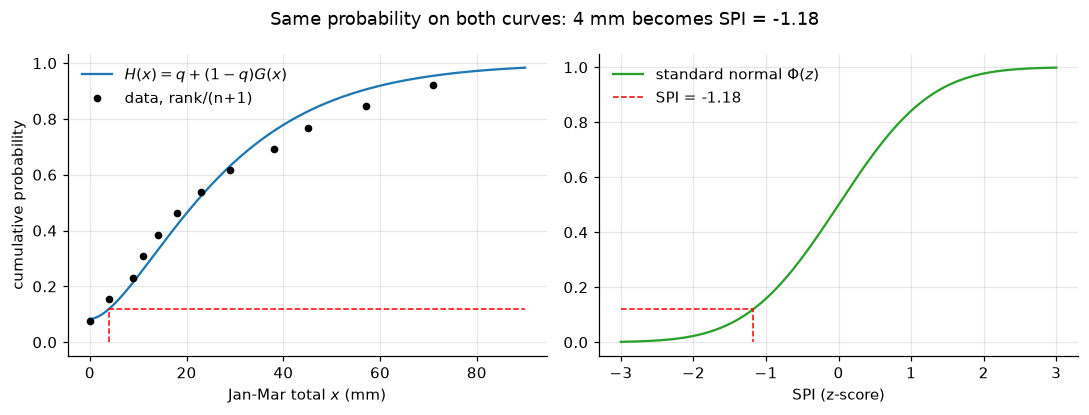

In [6]:
# Figure 1: the SPI as a probability match, for the hand example
xx = np.linspace(0, 90, 300)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].plot(xx, q + (1 - q) * stats.gamma.cdf(xx, alpha, scale=beta), "tab:blue", label="$H(x)=q+(1-q)G(x)$")
xs = np.sort(x)
ax[0].plot(xs, np.arange(1, 13) / 13, "ko", ms=4, label="data, rank/(n+1)")
ax[0].plot([4, 4, 90], [0, H4, H4], "r--", lw=1)
ax[0].set_xlabel("Jan-Mar total $x$ (mm)"); ax[0].set_ylabel("cumulative probability"); ax[0].legend(frameon=False)
zz = np.linspace(-3, 3, 300)
ax[1].plot(zz, stats.norm.cdf(zz), "tab:green", label="standard normal $\\Phi(z)$")
z4 = stats.norm.ppf(H4)
ax[1].plot([-3, z4, z4], [H4, H4, 0], "r--", lw=1, label=f"SPI = {z4:.2f}")
ax[1].set_xlabel("SPI (z-score)"); ax[1].legend(frameon=False)
fig.suptitle("Same probability on both curves: 4 mm becomes SPI = -1.18")
plt.tight_layout(); plt.show()

The scipy maximum-likelihood fit gives almost the same shape and scale as Thom's formulas, so the approximation is good enough. The data points follow the fitted curve on the left, and the red line carries the probability 0.12 across to the right panel.

## 5) SPI-3 and SPI-12 for the Chattooga

The simple indicators already flag the dry years: 2000 and 2001 were about 29 % and 28 % below the 25-year normal of 1,742 mm (IMD: deficient; decile 1), and 2007 about 25 % below. Now the SPI function of the hand example runs on the real record. For each calendar month we collect the $k$-month totals of all 25 years, fit a gamma to them, and convert each total to an SPI. SPI-3 follows short dry spells; SPI-12 follows the slow, year-long deficits that matter for rivers and reservoirs.

SPI-3: mean -0.00, sd 1.00, share of months <= -1: 16.8 %, lowest -2.27 in 2006-04
SPI-12: mean -0.00, sd 1.00, share of months <= -1: 18.0 %, lowest -2.12 in 2001-04
SPI-1 of October 2000 (the zero month): -1.75


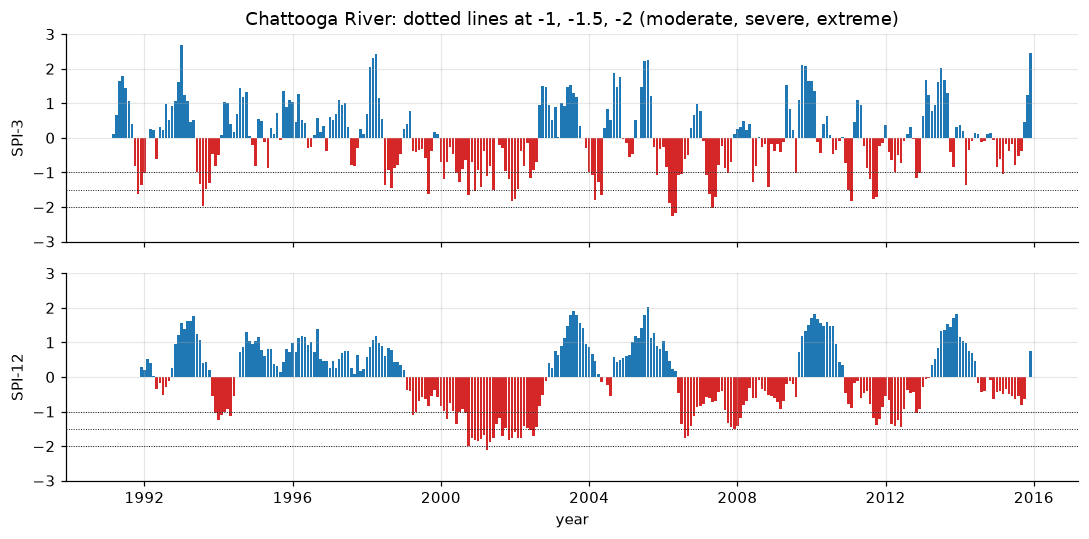

In [7]:
def spi(series, k):
    """SPI-k of a monthly series: k-month totals, one gamma fit per calendar month (WMO 2012)."""
    xk = series.rolling(k).sum()
    out = pd.Series(np.nan, index=series.index)
    for month in range(1, 13):
        sel = xk.index.month == month
        out[sel] = spi_values(xk[sel].values)
    return out

spi3, spi12 = spi(mon.prcp_mm, 3), spi(mon.prcp_mm, 12)
for name, s in (("SPI-3", spi3), ("SPI-12", spi12)):
    print(f"{name}: mean {s.mean():+.2f}, sd {s.std():.2f}, share of months <= -1: {100 * (s.dropna() <= -1).mean():.1f} %, "
          f"lowest {s.min():.2f} in {s.idxmin():%Y-%m}")
print("SPI-1 of October 2000 (the zero month):", round(spi(mon.prcp_mm, 1)["2000-10-01"], 2))

# Figure 2: SPI-3 and SPI-12
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
for a, s, name in ((ax[0], spi3, "SPI-3"), (ax[1], spi12, "SPI-12")):
    a.bar(s.index, s.values, width=25, color=np.where(s.values < 0, "tab:red", "tab:blue"))
    for lev in (-1, -1.5, -2): a.axhline(lev, color="k", lw=0.6, ls=":")
    a.set_ylabel(name); a.set_ylim(-3, 3)
ax[1].set_xlabel("year"); ax[0].set_title("Chattooga River: dotted lines at -1, -1.5, -2 (moderate, severe, extreme)")
plt.tight_layout(); plt.show()

Both indices have mean about 0 and standard deviation about 1, as they should, and about one month in six has an SPI of -1 or below (for a normal variable it would be 16 %). SPI-3 flickers from month to month; SPI-12 shows the long dry periods clearly: 1998 to 2002 (lowest SPI-12, -2.12, in April 2001) and 2006 to 2008, the two known droughts of the region. The single dry month, October 2000 with no rain at all, gets an SPI-1 of only -1.75: with one zero in 25 Octobers, $q=0.04$ caps the index, just as in the hand example.

## 6) SPEI: adding the evaporation demand

Rain is only the supply. A hot month evaporates more, so the same rain leaves less water. The **Standardized Precipitation Evapotranspiration Index** (SPEI; Vicente-Serrano et al. 2010) applies the SPI recipe to the climatic water balance $W=P-PET$ instead of $P$. Because $W$ can be negative, the gamma cannot be used; the original SPEI fits a three-parameter **log-logistic** distribution by probability-weighted moments, which the code below does in a few lines. Everything else (k-month sums, one fit per calendar month, conversion to z) is unchanged. Here PET is the Oudin estimate stored in the dataset.

correlation SPI-12 vs SPEI-12: 0.995; lowest SPEI-12 -1.95 in 2006-08


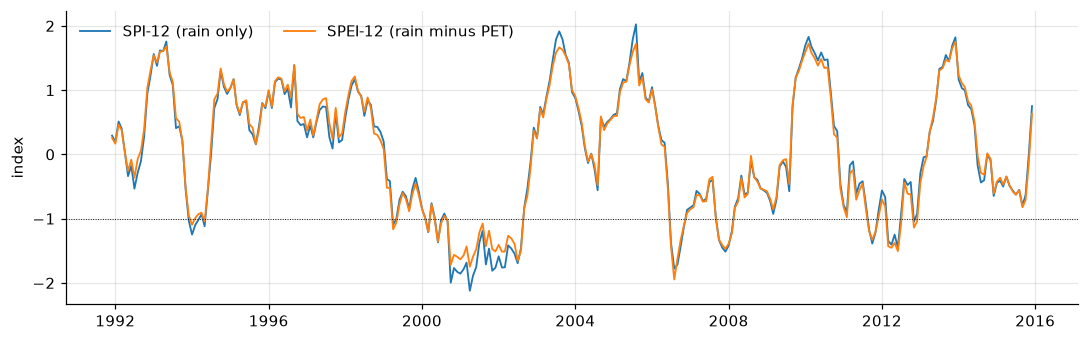

In [8]:
def loglogistic_fit(w):
    """Log-logistic scale, shape and location by probability-weighted moments (Vicente-Serrano et al. 2010)."""
    w = np.sort(w); F = (np.arange(1, len(w) + 1) - 0.35) / len(w)
    w0, w1, w2 = (np.mean((1 - F) ** s * w) for s in (0, 1, 2))
    shape = (2 * w1 - w0) / (6 * w1 - w0 - 6 * w2)
    g = gamma_fn(1 + 1 / shape) * gamma_fn(1 - 1 / shape)
    scale = (w0 - 2 * w1) * shape / g
    return scale, shape, w0 - scale * g

def spei(W, k):
    wk = W.rolling(k).sum()
    out = pd.Series(np.nan, index=W.index)
    for month in range(1, 13):
        sel = wk.index.month == month
        scale, shape, loc = loglogistic_fit(wk[sel].dropna().values)
        F = stats.fisk.cdf(wk[sel].values, shape, loc=loc, scale=scale)   # fisk = log-logistic in scipy
        out[sel] = stats.norm.ppf(np.clip(F, 1e-6, 1 - 1e-6))
    return out

W = mon.prcp_mm - mon.pet_mm
spei12 = spei(W, 12)
print(f"correlation SPI-12 vs SPEI-12: {spi12.corr(spei12):.3f}; lowest SPEI-12 {spei12.min():.2f} in {spei12.idxmin():%Y-%m}")

# Figure 3: SPI-12 and SPEI-12
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(spi12, color="tab:blue", lw=1.2, label="SPI-12 (rain only)")
ax.plot(spei12, color="tab:orange", lw=1.2, label="SPEI-12 (rain minus PET)")
ax.axhline(-1, color="k", lw=0.6, ls=":"); ax.set_ylabel("index"); ax.legend(frameon=False, ncol=2)
plt.tight_layout(); plt.show()

In this humid catchment the two indices move almost together (correlation 0.995): year-to-year swings in rain are much larger than swings in PET, while PET changes little from year to year (its annual total stays between about 930 and 1,020 mm). The SPEI becomes important when temperature changes, which is the climate-change question of Lecture 27.

## 7) A streamflow index and drought propagation

For **hydrological drought** we apply the same recipe to monthly streamflow: the **standardized streamflow index** (SSI; e.g. Vicente-Serrano et al. 2012) is the SPI recipe with $Q$ in place of $P$. Flow is never zero in this river, so $q=0$, and we keep the gamma for simplicity (other distributions are also used for flow). Comparing SSI-3 with the SPI shows how a rain deficit propagates into the river.

corr(SPI-k, SSI-3): {1: 0.36, 3: 0.76, 6: 0.86, 9: 0.84, 12: 0.77, 18: 0.68, 24: 0.61}
corr(SPI-3 now, SSI-3 'lag' months later): {0: 0.76, 1: 0.81, 2: 0.72, 3: 0.57, 4: 0.45, 5: 0.37, 6: 0.28}
lowest SSI-3: -2.04 in 2001-02


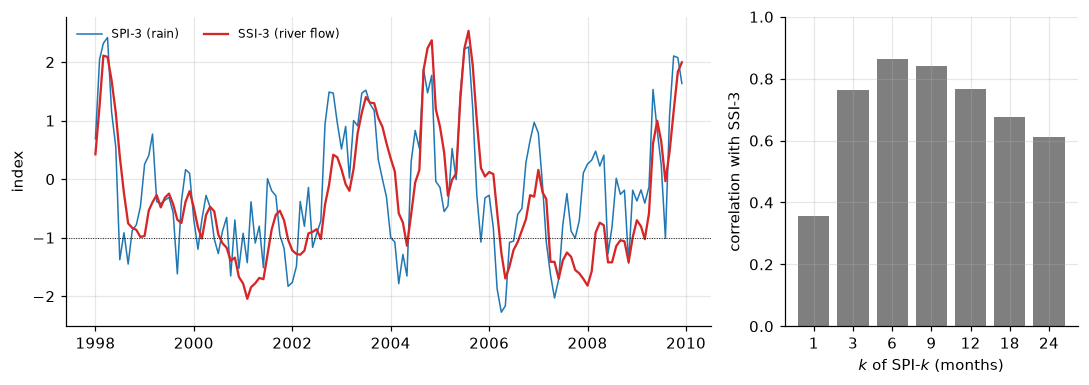

In [9]:
ssi3 = spi(mon.q_mm, 3)                          # same function, flow instead of rain
ks = [1, 3, 6, 9, 12, 18, 24]
r_k = [spi(mon.prcp_mm, k).corr(ssi3) for k in ks]
r_lag = [spi3.corr(ssi3.shift(-lag)) for lag in range(7)]
print("corr(SPI-k, SSI-3):", {k: round(float(r), 2) for k, r in zip(ks, r_k)})
print("corr(SPI-3 now, SSI-3 'lag' months later):", {lag: round(float(r), 2) for lag, r in enumerate(r_lag)})
print(f"lowest SSI-3: {ssi3.min():.2f} in {ssi3.idxmin():%Y-%m}")

# Figure 4: propagation from rain to river
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={"width_ratios": [2.2, 1]})
sl = slice("1998-01", "2009-12")
ax[0].plot(spi3[sl], color="tab:blue", lw=1, label="SPI-3 (rain)")
ax[0].plot(ssi3[sl], color="tab:red", lw=1.5, label="SSI-3 (river flow)")
ax[0].axhline(-1, color="k", lw=0.6, ls=":"); ax[0].legend(frameon=False, ncol=2, loc="upper left", fontsize=8); ax[0].set_ylabel("index")
ax[1].bar([str(k) for k in ks], r_k, color="tab:gray")
ax[1].set_xlabel("$k$ of SPI-$k$ (months)"); ax[1].set_ylabel("correlation with SSI-3"); ax[1].set_ylim(0, 1)
plt.tight_layout(); plt.show()

Two signs of propagation appear. First, SSI-3 matches the rain of the past **six** months best (correlation 0.86 with SPI-6, against 0.76 with SPI-3): the soil and groundwater store remember rain for months, so the river responds to a longer accumulation than its own 3-month window. Second, SPI-3 agrees best with the SSI-3 of **one month later** (0.81, against 0.76 for the same month): the river lags the rain. In the figure the short dips of SPI-3 are often missing from the flow, while the long deficits of 1999 to 2002 and 2007 to 2008 show up strongly in it and last longer. That is exactly the chain of Section 2.1, seen in data.

## Summary

- A drought is a temporary shortage relative to the local normal; aridity is permanent, and water scarcity is caused by demand.
- By impact: meteorological, agricultural, hydrological and socioeconomic drought, linked by propagation with growing lags. By timing (Thornthwaite): permanent, seasonal, contingent and invisible. Newer terms: flash, groundwater, snow, ecological drought and megadrought.
- Percent of normal, departure (IMD classes) and deciles are simple but do not account for how variable the rain is.
- SPI-$k$: $k$-month totals per calendar month, gamma fit (Thom: $A=\ln\bar x-\overline{\ln x}$, $\alpha=(1+\sqrt{1+4A/3})/(4A)$, $\beta=\bar x/\alpha$), $H=q+(1-q)G$, SPI $=\Phi^{-1}(H)$. Hand example: 4 mm gives SPI $=-1.18$, moderately dry, although it is only 15 % of normal.
- SPEI applies the recipe to $W=P-PET$, the SSI to streamflow. On the Chattooga the river follows the rain of the past six months, one month late.

## Check your understanding

1. Jaisalmer gets 200 mm in a year with a normal of 210 mm; Mumbai gets 1,800 mm with a normal of 2,400 mm. Which, if either, is in drought, and which indicator in this lecture would you use to compare them fairly?
2. In the hand example, why can no year score an SPI below $-1.38$? What would that floor be with two zeros in 12 years?
3. Why does the streamflow index match SPI-6 better than SPI-3, and which SPI would you expect to match a groundwater index?

## Try it yourself

- In the workbook, change the 4 mm year to 2 mm and to 8 mm. How do the percent of normal and the SPI change? Which changes more?
- Compute SPI-6 and SPI-24 for the Chattooga and plot them with SPI-3 and SPI-12. Which one shows the 2007 to 2008 drought most clearly?
- Recompute SPI-3 with the exact maximum-likelihood gamma (`stats.gamma.fit(x, floc=0)`) instead of Thom's formulas, and plot the difference.

```{note} Sources
Written for **CE524 Applied Hydroclimatology**. Definitions and types: Mishra, A. K., & Singh, V. P. (2010). A review of drought concepts. *J. Hydrology, 391*, 202&ndash;216; Thornthwaite, C. W. (1947). Climate and moisture conservation. *Annals of the Association of American Geographers, 37*, 87&ndash;100; Van Loon, A. F. (2015). Hydrological drought explained. *WIREs Water, 2*, 359&ndash;392; Otkin, J. A., et al. (2018). Flash droughts: a review and assessment of the challenges imposed by rapid-onset droughts in the United States. *BAMS, 99*, 911&ndash;919. Indices: McKee, T. B., Doesken, N. J., & Kleist, J. (1993). The relationship of drought frequency and duration to time scales. *8th Conf. on Applied Climatology*, AMS, 179&ndash;184; World Meteorological Organization (2012). *Standardized Precipitation Index User Guide* (WMO-No. 1090); Edwards, D. C., & McKee, T. B. (1997). *Characteristics of 20th century drought in the United States at multiple time scales*. Colorado State University, Climatology Report 97-2; Thom, H. C. S. (1958). A note on the gamma distribution. *Monthly Weather Review, 86*, 117&ndash;122; Gibbs, W. J., & Maher, J. V. (1967). *Rainfall deciles as drought indicators*. Bureau of Meteorology Bulletin 48, Melbourne; Vicente-Serrano, S. M., Begueria, S., & Lopez-Moreno, J. I. (2010). A multiscalar drought index sensitive to global warming: the SPEI. *J. Climate, 23*, 1696&ndash;1718; Vicente-Serrano, S. M., et al. (2012). Accurate computation of a streamflow drought index. *J. Hydrologic Engineering, 17*, 318&ndash;332. Rainfall departure classes: India Meteorological Department. Data: Chattooga River, Daymet v4 and USGS NWIS (see Lecture 7). The explanations, hand example, workbook and figures were made for this course. Related lectures: 7, 10, 14, 17, 27.

Text under CC BY-SA 4.0, code additionally under the MIT License; full attribution in [CREDITS.md](https://github.com/drvivekhydro/hydroclimatology/blob/main/CREDITS.md).
```